In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
file_path = "C:\\Users\\HP\\OneDrive\\Desktop\\fez\\Electricity-Forecasting\\data\\raw\\household_power_consumption.txt"

data = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
data.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
data.tail()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075254,26/11/2010,20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2075255,26/11/2010,20:59:00,0.944,0.0,240.00,4.0,0.0,0.0,0.0
2075256,26/11/2010,21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2075257,26/11/2010,21:01:00,0.934,0.0,239.70,3.8,0.0,0.0,0.0
2075258,26/11/2010,21:02:00,0.932,0.0,239.55,3.8,0.0,0.0,0.0


In [6]:
data.shape

(2075259, 9)

In [7]:
data.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 176.0 MB


In [9]:
data.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [10]:
missing_percentage = (data.isnull().sum() / len(data)) * 100

print(missing_percentage)

Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64


In [11]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

In [12]:
for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

In [13]:
data["Datetime"] = pd.to_datetime(
    data["Date"] + " " + data["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

In [14]:
data[["Date", "Time", "Datetime"]].head()

,Date,Time,Datetime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00


In [15]:
data = data.sort_values(by="Datetime")

data = data.reset_index(drop=True)

In [16]:
clean_data = data.dropna(
    subset=["Datetime", "Global_active_power"]
).copy()

In [17]:
clean_data["Energy_kWh"] = clean_data["Global_active_power"] / 60

In [18]:
clean_data["Day"] = clean_data["Datetime"].dt.date

In [19]:
daily_consumption = clean_data.groupby("Day")["Energy_kWh"].sum()

In [20]:
daily_consumption = daily_consumption.reset_index()

daily_consumption.columns = ["Date", "Daily_Consumption_kWh"]

In [21]:
daily_consumption.head(10)

,Date,Daily_Consumption_kWh
0,2006-12-16,20.152933
1,2006-12-17,56.507667
2,2006-12-18,36.730433
3,2006-12-19,27.769900
4,2006-12-20,37.095800
5,2006-12-21,28.610400
6,2006-12-22,39.022300
7,2006-12-23,79.556433
8,2006-12-24,42.500200
9,2006-12-25,45.718667


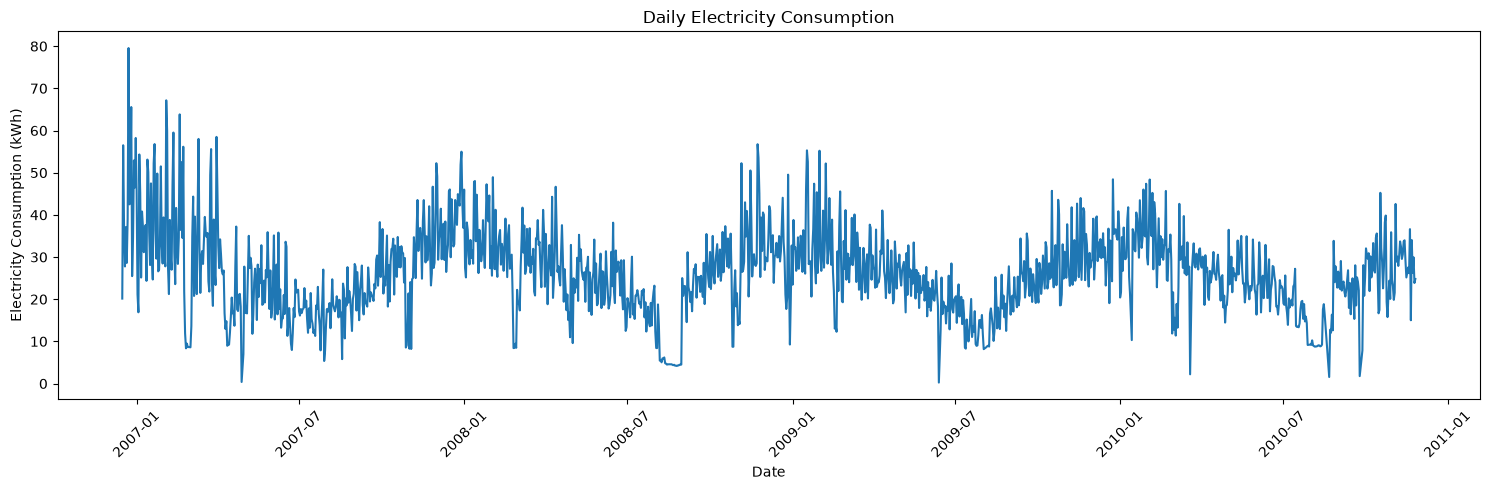

In [22]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_consumption["Date"],
    daily_consumption["Daily_Consumption_kWh"]
)

plt.title("Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Electricity Consumption (kWh)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [23]:
output_path ="C:\\Users\\HP\\OneDrive\\Desktop\\fez\\Electricity-Forecasting\\data\\processed\\daily_consumption.csv"
daily_consumption.to_csv(output_path, index=False)

print("Daily consumption dataset saved successfully!")

Daily consumption dataset saved successfully!


In [24]:
# Count valid electricity readings for each day

daily_quality = clean_data.groupby("Day").size().reset_index(name="Valid_Readings")

# Calculate percentage of daily data completeness

daily_quality["Completeness_Percentage"] = (
    daily_quality["Valid_Readings"] / 1440
) * 100

daily_quality.head(10)

,Day,Valid_Readings,Completeness_Percentage
0,2006-12-16,396,27.500000
1,2006-12-17,1440,100.000000
2,2006-12-18,1440,100.000000
3,2006-12-19,1440,100.000000
4,2006-12-20,1440,100.000000
5,2006-12-21,1438,99.861111
6,2006-12-22,1440,100.000000
7,2006-12-23,1440,100.000000
8,2006-12-24,1440,100.000000
9,2006-12-25,1440,100.000000


In [25]:
incomplete_days = daily_quality[
    daily_quality["Completeness_Percentage"] < 99
]

print("Total days:", len(daily_quality))

print("Incomplete days:", len(incomplete_days))

print("Percentage of incomplete days:",
      (len(incomplete_days) / len(daily_quality)) * 100)

Total days: 1433
Incomplete days: 22
Percentage of incomplete days: 1.5352407536636425


In [26]:
valid_days = daily_quality[
    daily_quality["Completeness_Percentage"] >= 99
]["Day"]

In [29]:
daily_consumption["Day"] = pd.to_datetime(
    daily_consumption["Date"]
).dt.date

daily_consumption = daily_consumption[
    daily_consumption["Day"].isin(valid_days)
].copy()

daily_consumption = daily_consumption.drop(columns=["Day"])

daily_consumption.head()

,Date,Daily_Consumption_kWh
1,2006-12-17,56.507667
2,2006-12-18,36.730433
3,2006-12-19,27.769900
4,2006-12-20,37.095800
5,2006-12-21,28.610400


In [30]:
print("Final dataset shape:", daily_consumption.shape)

print("\nMissing values:")
print(daily_consumption.isnull().sum())

print("\nStatistical summary:")
print(daily_consumption["Daily_Consumption_kWh"].describe())

Final dataset shape: (1411, 2)

Missing values:
Date                     0
Daily_Consumption_kWh    0
dtype: int64

Statistical summary:
count    1411.000000
mean       26.206385
std        10.006795
min         4.171633
25%        19.672450
50%        25.937567
75%        31.724600
max        79.556433
Name: Daily_Consumption_kWh, dtype: float64


In [31]:
daily_consumption.to_csv(
    "C:\\Users\\HP\\OneDrive\\Desktop\\fez\\Electricity-Forecasting\\data\\processed\\daily_consumption.csv",
    index=False
)

print("Final cleaned dataset saved!")

Final cleaned dataset saved!


In [32]:
data = pd.read_csv("../data/processed/daily_consumption.csv")

data.head()

,Date,Daily_Consumption_kWh
0,2006-12-17,56.507667
1,2006-12-18,36.730433
2,2006-12-19,27.769900
3,2006-12-20,37.095800
4,2006-12-21,28.610400


In [33]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1411 entries, 0 to 1410
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   1411 non-null   str    
 1   Daily_Consumption_kWh  1411 non-null   float64
dtypes: float64(1), str(1)
memory usage: 36.0 KB


In [34]:
data["Date"] = pd.to_datetime(data["Date"])

In [35]:
print("Average Daily Consumption:",
      data["Daily_Consumption_kWh"].mean(), "kWh")

print("Maximum Daily Consumption:",
      data["Daily_Consumption_kWh"].max(), "kWh")

print("Minimum Daily Consumption:",
      data["Daily_Consumption_kWh"].min(), "kWh")

print("Total Electricity Consumption:",
      data["Daily_Consumption_kWh"].sum(), "kWh")

Average Daily Consumption: 26.206384738955823 kWh
Maximum Daily Consumption: 79.55643333333333 kWh
Minimum Daily Consumption: 4.171633333333333 kWh
Total Electricity Consumption: 36977.20886666667 kWh


In [36]:
data["Daily_Consumption_kWh"].describe()

count    1411.000000
mean       26.206385
std        10.006795
min         4.171633
25%        19.672450
50%        25.937567
75%        31.724600
max        79.556433
Name: Daily_Consumption_kWh, dtype: float64

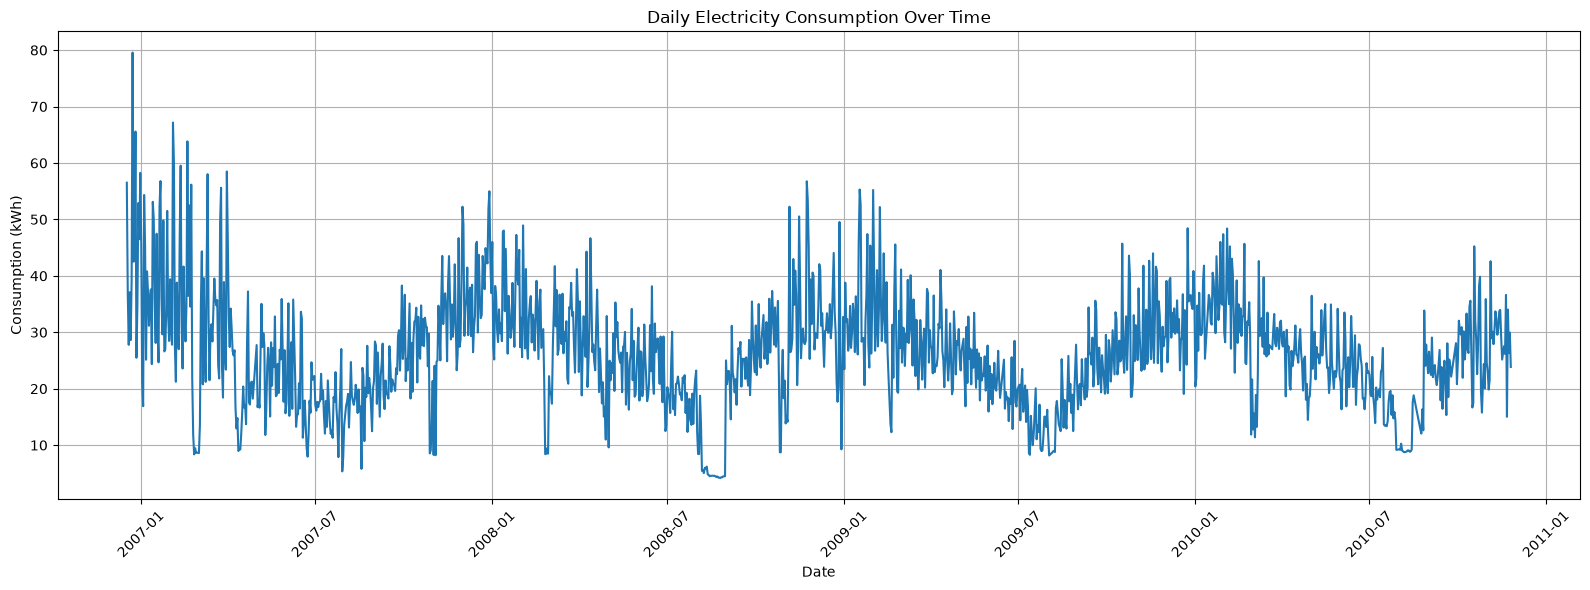

In [37]:
plt.figure(figsize=(16, 6))

plt.plot(
    data["Date"],
    data["Daily_Consumption_kWh"]
)

plt.title("Daily Electricity Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")

plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [38]:
data["Year"] = data["Date"].dt.year

data["Month"] = data["Date"].dt.month

data["Month_Name"] = data["Date"].dt.month_name()

In [39]:
monthly_consumption = data.groupby(
    ["Year", "Month", "Month_Name"]
)["Daily_Consumption_kWh"].sum().reset_index()

monthly_consumption.head()

,Year,Month,Month_Name,Daily_Consumption_kWh
0,2006,12,December,676.735100
1,2007,1,January,1150.197700
2,2007,2,February,941.481433
3,2007,3,March,981.036533
4,2007,4,April,578.965100


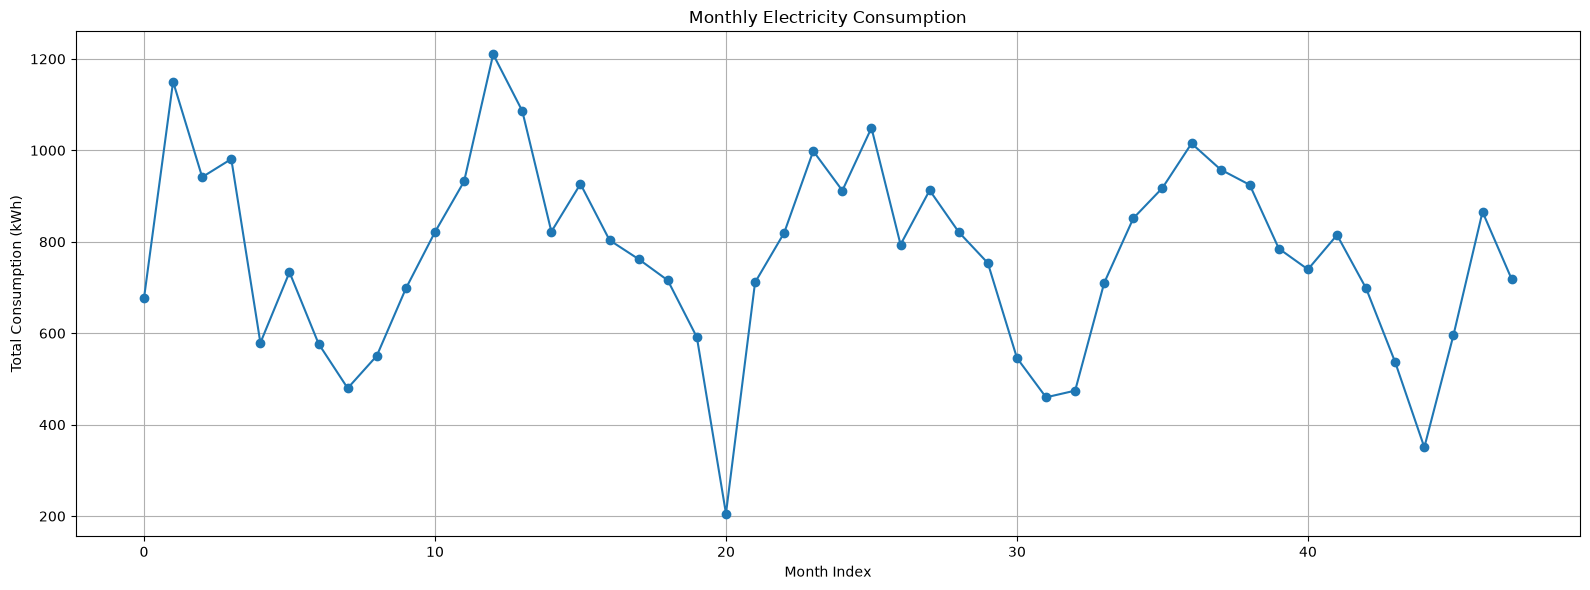

In [40]:
plt.figure(figsize=(16, 6))

plt.plot(
    monthly_consumption.index,
    monthly_consumption["Daily_Consumption_kWh"],
    marker="o"
)

plt.title("Monthly Electricity Consumption")
plt.xlabel("Month Index")
plt.ylabel("Total Consumption (kWh)")

plt.grid(True)
plt.tight_layout()
plt.show()

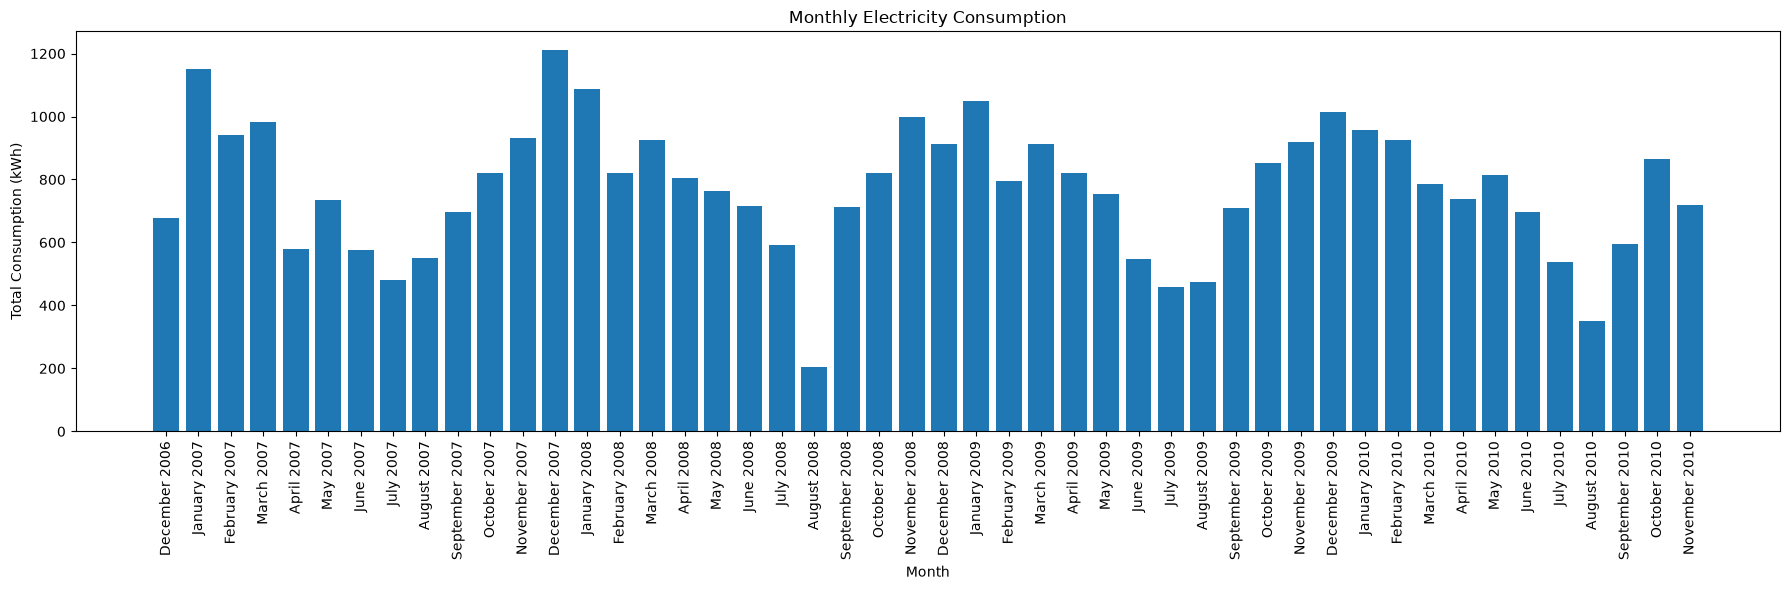

In [41]:
monthly_consumption["Month_Label"] = (
    monthly_consumption["Month_Name"] + " " +
    monthly_consumption["Year"].astype(str)
)

plt.figure(figsize=(18, 6))

plt.bar(
    monthly_consumption["Month_Label"],
    monthly_consumption["Daily_Consumption_kWh"]
)

plt.title("Monthly Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Total Consumption (kWh)")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [42]:
data["Day_of_Week"] = data["Date"].dt.day_name()

In [43]:
weekday_consumption = data.groupby(
    "Day_of_Week"
)["Daily_Consumption_kWh"].mean()

weekday_consumption

Day_of_Week
Friday       25.026690
Monday       24.018217
Saturday     30.006823
Sunday       29.326194
Thursday     23.530370
Tuesday      25.725080
Wednesday    25.968669
Name: Daily_Consumption_kWh, dtype: float64

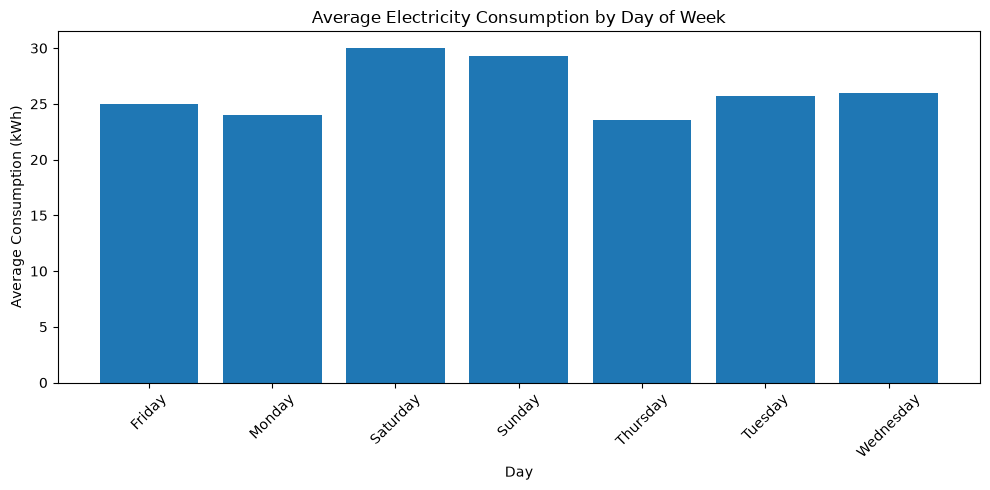

In [44]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_consumption.index,
    weekday_consumption.values
)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Consumption (kWh)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

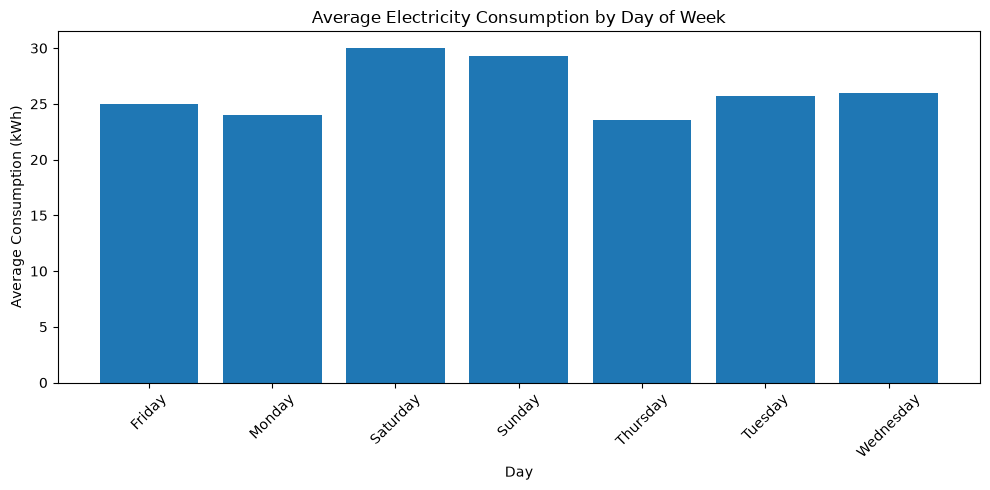

In [45]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_consumption.index,
    weekday_consumption.values
)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Consumption (kWh)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
hourly_data = pd.read_csv(
    "C:\\Users\\HP\\OneDrive\\Desktop\\fez\\Electricity-Forecasting\\data\\raw\\household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

In [48]:
hourly_data["Global_active_power"] = pd.to_numeric(
    hourly_data["Global_active_power"],
    errors="coerce"
)

In [49]:
hourly_data["Datetime"] = pd.to_datetime(
    hourly_data["Date"] + " " + hourly_data["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

In [50]:
hourly_data["Hour"] = hourly_data["Datetime"].dt.hour

In [51]:
hourly_consumption = hourly_data.groupby(
    "Hour"
)["Global_active_power"].mean()

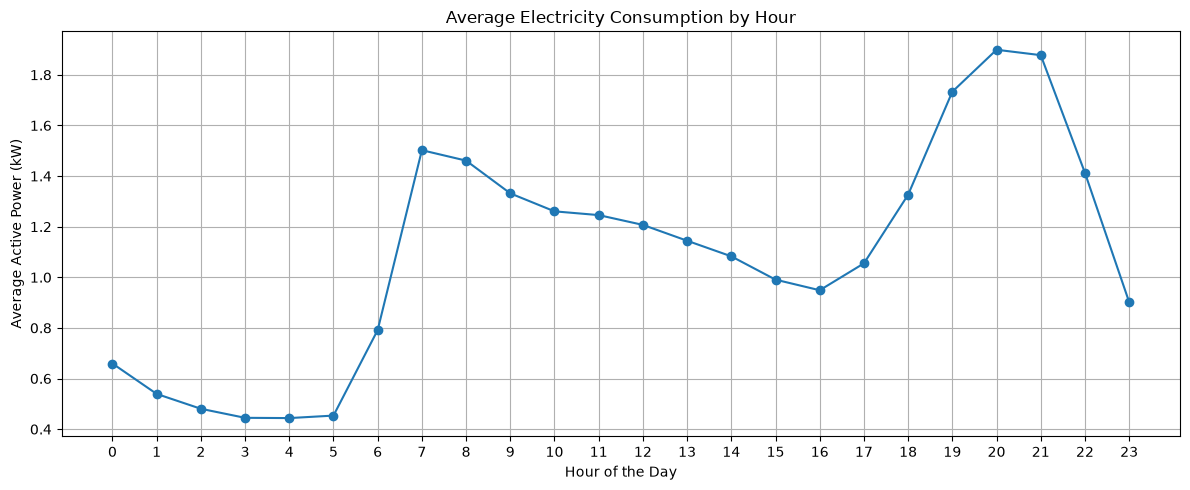

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker="o"
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Active Power (kW)")

plt.xticks(range(24))
plt.grid(True)

plt.tight_layout()
plt.show()

In [53]:
Q1 = data["Daily_Consumption_kWh"].quantile(0.25)

Q3 = data["Daily_Consumption_kWh"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + (1.5 * IQR)

lower_limit = Q1 - (1.5 * IQR)

In [54]:
high_consumption_days = data[
    data["Daily_Consumption_kWh"] > upper_limit
]

print("Number of unusually high consumption days:",
      len(high_consumption_days))

high_consumption_days.head()

Number of unusually high consumption days: 31


,Date,Daily_Consumption_kWh,Year,Month,Month_Name,Day_of_Week
0,2006-12-17,56.507667,2006,12,December,Sunday
6,2006-12-23,79.556433,2006,12,December,Saturday
9,2006-12-26,65.568500,2006,12,December,Tuesday
12,2006-12-29,52.906533,2006,12,December,Friday
14,2006-12-31,58.236600,2006,12,December,Sunday


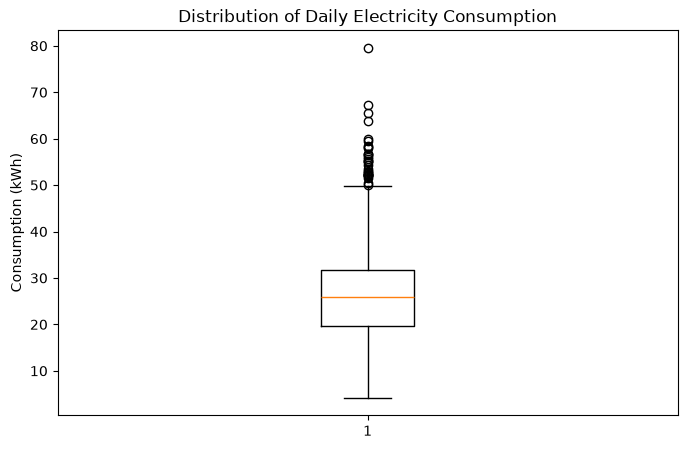

In [55]:
plt.figure(figsize=(8, 5))

plt.boxplot(data["Daily_Consumption_kWh"])

plt.title("Distribution of Daily Electricity Consumption")
plt.ylabel("Consumption (kWh)")

plt.show()

In [ ]:
monthly_consumption.to_csv(
    "C:\\Users\\HP\\OneDrive\\Desktop\\fez\\Electricity-Forecasting\\data\\processed\\monthly_consumption.csv",
    index=False
)

print("Monthly analysis saved successfully!")

In [56]:
weekday_consumption.to_csv(
      "C:\\Users\\HP\\OneDrive\\Desktop\\fez\\Electricity-Forecasting\\data\\processed\\weekly_consumption.csv"
)

print("Weekday analysis saved successfully!")

Weekday analysis saved successfully!
